<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(36, 26, 8, 0.18), rgba(36, 26, 8, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="width:100%; max-width:850px; box-sizing:border-box; margin:0 auto; text-align:center; padding:48px 32px 40px 32px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:13px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 12px rgba(0,0,0,0.95); letter-spacing:4px;">Earth-Space AI Research (ESAIR) Lab · Community Prediction Competition</p><p style="margin:14px 0 0 0; font-family:Georgia, 'Times New Roman', serif; font-size:44px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 24px rgba(0,0,0,0.95); line-height:1.1;">Solar Filament Segmentation Challenge 2026</p><p style="margin:10px 0 0 0; font-family:Georgia, 'Times New Roman', serif; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:2px;">Pieter Bruegel the Elder | Landscape with the Fall of Icarus, c. 1560 | Public Domain</p><div style="margin-top:38px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:14px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">ABOUT THE TASK</p><div style="margin-top:16px;"><div style="display:inline-block; vertical-align:top; width:260px; max-width:calc(100% - 24px); box-sizing:border-box; margin:12px; text-align:center;"><p style="margin:0 0 10px 0; font-family:Georgia, 'Times New Roman', serif; font-size:12px; font-weight:bold; color:#EAEAEA; text-shadow:0 2px 8px rgba(0,0,0,0.95); letter-spacing:3px;">TYPE</p><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:20px; font-weight:800; color:#FFFFFF; text-shadow:0 3px 14px rgba(0,0,0,0.95); line-height:1.4;">Segmentation</p></div><div style="display:inline-block; vertical-align:top; width:260px; max-width:calc(100% - 24px); box-sizing:border-box; margin:12px; text-align:center;"><p style="margin:0 0 10px 0; font-family:Georgia, 'Times New Roman', serif; font-size:12px; font-weight:bold; color:#EAEAEA; text-shadow:0 2px 8px rgba(0,0,0,0.95); letter-spacing:3px;">GOAL</p><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:20px; font-weight:800; color:#FFFFFF; text-shadow:0 3px 14px rgba(0,0,0,0.95); line-height:1.4;">Segmentation of solar filaments</p></div></div></div><div style="margin-top:38px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:14px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">ABOUT THIS NOTEBOOK</p><div style="width:100%; max-width:700px; box-sizing:border-box; margin:20px auto 0 auto; text-align:left;"><p style="margin:0 0 16px 0; font-family:Georgia, 'Times New Roman', serif; font-size:16px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.75; text-align:justify;"><span style="color:#EAD98B; font-weight:bold;">— </span> This report describes the pipeline of my solution. Long story short, the main idea of my model is to use attention to make the network more aware of the general geometry of filaments. There is a more detailed explanation on my GitHub (if you’re curious, I left my report in the solution repository). </p><p style="margin:0 0 16px 0; font-family:Georgia, 'Times New Roman', serif; font-size:16px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.75; text-align:justify;"><span style="color:#EAD98B; font-weight:bold;">— </span> Is this the best model? Probably not, but it was a lot of fun.</p></div></div></div></div>

In [52]:
import json
import math
import os
import random
from collections import defaultdict
from pathlib import Path
from typing import Callable, Optional

import cv2
import numpy as np
import optuna
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import uniform_filter
from pycocotools import mask as mask_util
from torch.utils.data import DataLoader, Dataset
from torchmetrics.classification import BinaryF1Score, BinaryJaccardIndex, BinaryPrecision, BinaryRecall
from torchvision.models import ResNet34_Weights
from tqdm import tqdm

os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"
cv2.setNumThreads(0)
cv2.ocl.setUseOpenCL(False)

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Settings</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> Everything downstream reads from here, so changing the resolution or the seed changes the whole pipeline.</p></div></div>

In [2]:
class Config:
    seed: int = 567
    pin_memory: bool = True
    batch_size: int = 2
    resolution: int = 1024
    val_size: float = 0.1
    num_workers: int = 2
    lr: float = 1e-4
    shuffle: bool = True
    device: torch.device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    
    train = "data/MAGFiLO_1.0_Kaggle_2026/train/train_images"
    test = "data/MAGFiLO_1.0_Kaggle_2026/test/test_images"
    metadata = "data/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    silso = "data/SILSO.csv"
    
    def __repr__(self) -> str:
        return f"""
        {"="*12} Config {"="*12}
        ==> Seed: {self.seed}
        ==> Device: {self.device}
        ==> Resolution: {self.resolution}
        ==> Batch size: {self.batch_size}
        ==> Num workers: {self.num_workers}
        ==> Pin memory: {self.pin_memory}
        ==> Shuffle: {self.shuffle}
        ==> Val size: {self.val_size}
        ==> LR: {self.lr}
        {"="*32}
        """

CFG = Config()

CFG


        ============ Config ============
        ==> Seed: 567
        ==> Device: cuda
        ==> Resolution: 1024
        ==> Batch size: 2
        ==> Num workers: 2
        ==> Pin memory: True
        ==> Shuffle: True
        ==> Val size: 0.1
        ==> LR: 0.0001
        

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Loss</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> Each filament has two targets: the mask and its spine. The model predicts both, and the loss is the mask loss plus 0.1 times the spine loss. The spine only helps the training, it is not used in the submission.</p></div></div>

In [3]:
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, smooth=1.0):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.dice_weight = (1 - bce_weight)
        self.smooth = smooth

    def forward(self, logits, target):
        bce = self.bce(logits, target)

        probs = torch.sigmoid(logits)
        dims = tuple(range(1, probs.ndim))
        intersection = (probs * target).sum(dims)
        cardinality = probs.sum(dims) + target.sum(dims)
        dice = 1 - (2 * intersection + self.smooth) / (cardinality + self.smooth)

        return self.bce_weight * bce + self.dice_weight * dice.mean()


class SegSpineLoss(nn.Module):
    def __init__(self, spine_weight=0.1, seg_only=False):
        super().__init__()
        self.seg_loss = BCEDiceLoss()
        self.spine_loss = BCEDiceLoss()
        self.spine_weight = spine_weight
        self.seg_only = seg_only

    def forward(self, output, target):
        seg = self.seg_loss(output[:, :1], target[:, :1])

        if self.seg_only:
            return seg

        spine = self.spine_loss(output[:, 1:], target[:, 1:])
        return seg + self.spine_weight * spine

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Preprocessing</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> H-alpha images get darker towards the limb and change from one observation to another. So each image has its disk detected, its radial brightness flattened and its contrast equalized (CLAHE), and everything outside the disk is zeroed.</p></div></div>

In [4]:
# Actually, these are preprocessing utilities, not the actual preprocessing pipeline, which runs inside the SunDataset.
def solar_disk_detection(img):
    height, width = img.shape

    small = cv2.resize(
        (np.clip(img, 0, 1) * 255).astype(np.uint8),
        (256, 256),
        interpolation=cv2.INTER_AREA,
    )

    blur = cv2.GaussianBlur(small, (9, 9), 2.0)
    edges = cv2.Canny(blur, 30, 100)

    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        return width / 2, height / 2, min(width, height) * 0.45

    image_center = np.array([127.5, 127.5])
    candidates = []

    for contour in contours:
        area = cv2.contourArea(contour)
        if area < 1000:
            continue

        (x, y), r = cv2.minEnclosingCircle(contour)
        center_distance = np.linalg.norm(np.array([x, y]) - image_center)

        if r > 40 and center_distance < 50:
            candidates.append((area, x, y, r, contour))

    if not candidates:
        return width / 2, height / 2, min(width, height) * 0.45

    _, x, y, r, _ = max(candidates, key=lambda c: c[0])

    scale_x = width / 256
    scale_y = height / 256

    x *= scale_x
    y *= scale_y
    r *= (scale_x + scale_y) / 2

    return x, y, r

def disk_masking(height, width, center_x, center_y, radius):
    Y, X = np.ogrid[:height, :width]
    mask = np.hypot(X - center_x, Y - center_y) <= radius
    return mask

def radial_flattening(img, center_x, center_y, radius, mask, window_size=21):
    height, width = img.shape

    Y, X = np.ogrid[:height, :width]
    dist = np.hypot(X - center_x, Y - center_y).astype(np.int32)

    radius = int(radius)
    ring_index = np.clip(dist, 0, radius)

    masked_ring_index = ring_index[mask]
    masked_values = img[mask].astype(np.float64)

    ring_sums = np.bincount(masked_ring_index, weights=masked_values, minlength=radius + 1)
    ring_counts = np.bincount(masked_ring_index, minlength=radius + 1).astype(np.float64)

    radial_profile = (ring_sums / np.maximum(ring_counts, 1)).astype(np.float32)

    has_pixels = ring_counts > 0
    if not has_pixels.all():
        radial_profile[~has_pixels] = np.interp(
            np.flatnonzero(~has_pixels),
            np.flatnonzero(has_pixels),
            radial_profile[has_pixels],
        )

    padded_profile = np.pad(radial_profile, window_size // 2, mode="edge")
    smoothing_kernel = np.ones(window_size) / window_size
    radial_profile = np.convolve(padded_profile, smoothing_kernel, mode="valid").astype(np.float32)

    background = radial_profile[ring_index]
    reference = float(np.mean(radial_profile))

    flattened = img * reference / np.maximum(background, 0.05)
    flattened = np.clip(flattened, 0, 1).astype(np.float32)
    return flattened

def clahe(img, mask, tileGridSize=(8, 8), clipLimit=2.0):
    img = np.where(mask, img, img[mask].mean())
    img = (np.clip(img, 0, 1) * 255.0 + 0.5).astype(np.uint8)

    clahe_op = cv2.createCLAHE(clipLimit=clipLimit, tileGridSize=tileGridSize)
    img = clahe_op.apply(img).astype(np.float32) / 255.0
    return img


def off_disk_zeroing(img, mask):
    img[~mask] = 0.0
    return img


def preprocess(img):
    height, width = img.shape
    center_x, center_y, radius = solar_disk_detection(img)
    mask = disk_masking(height, width, center_x, center_y, radius)
    img = radial_flattening(img, center_x, center_y, radius, mask, window_size=21)
    img = clahe(img, mask)
    img = off_disk_zeroing(img, mask)
    return img

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Augmentations</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

In [5]:
def augmentation(image, mask):
    if random.random() < 0.9:
        image = torch.flip(image, [-1])
        mask = torch.flip(mask, [-1])

    if random.random() < 0.9:
        image = torch.flip(image, [-2])
        mask = torch.flip(mask, [-2])

    if random.random() < 0.9:
        image, mask = random_rotation(image, mask)
        
    if random.random() < 0.25:
        image = random_gamma(image, min_gamma=0.5, max_gamma=1.5)
        
    return image, mask

# Augmentations
def random_rotation(image, mask, max_angle=45.0):
    h, w = image.shape[-2:]
    rad = math.radians(random.uniform(-max_angle, max_angle))
    cos, sin = math.cos(rad), math.sin(rad)
    theta = torch.tensor(
        [[cos, -sin * h / w, 0.0], [sin * w / h, cos, 0.0]],
        dtype=image.dtype,
    ).unsqueeze(0)

    grid = F.affine_grid(theta, (1, 1, h, w), align_corners=False)
    image = F.grid_sample(image.unsqueeze(0), grid, mode="bilinear", padding_mode="zeros", align_corners=False)[0]
    mask = F.grid_sample(mask.unsqueeze(0), grid, mode="nearest", padding_mode="zeros", align_corners=False)[0]
    return image, mask


def random_gamma(image, min_gamma=0.5, max_gamma=1.5):
    gamma = random.uniform(min_gamma, max_gamma)
    return torch.clamp(image, 0.0, 1.0) ** gamma

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Loading</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

In [6]:
# Data Loading
def read_image_metadata(path=None):
    if path is None:
        path = CFG.metadata
    with open(path) as f:
        coco = json.load(f)

    image_info = pd.DataFrame(coco["images"])
    annotations = pd.DataFrame(coco["annotations"])

    metadata = image_info.merge(annotations, left_on="id", right_on="image_id")[[
        "file_name",
        "url",
        "date_captured",
        "segmentation",
        "area",
        "iscrowd",
        "spine",
        "image_id",
        "bbox",
        "category_id",
    ]]

    metadata["date_captured"] = pd.to_datetime(metadata["date_captured"])
    metadata["month"] = metadata["date_captured"].dt.month
    metadata["year"] = metadata["date_captured"].dt.year
    return metadata

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> I split by time, not at random. Months are labeled by solar activity (low, moderate or high, from the SILSO sunspot number) so validation covers the whole cycle, and images are grouped in 90-day blocks. Training images too close (in days) to a validation image are discarded.</p></div></div>

In [7]:
def load_train_val(
    silso_path=CFG.silso,
    val_size=CFG.val_size,
    seed=CFG.seed,
    block_days=90,
    gap_days=30,
):
    metadata = read_image_metadata()
    SILSO = pd.read_csv(
        silso_path,
        sep=";",
        header=None,
        names=["year", "month", "day", "decimal_year", "sn", "sn_std", "n_obs", "definitive"],
    )[["year", "month", "day", "sn"]]
    SILSO = SILSO[SILSO["sn"] != -1]
    SILSO = SILSO[SILSO.year.between(metadata.year.min(), metadata.year.max())]

    sunspots = (
        SILSO.groupby(["year", "month"], as_index=False)["sn"].mean()
        .rename(columns={"sn": "monthly_mean_sunspot_number"})
    )
    sunspots["phase"] = pd.qcut(
        sunspots["monthly_mean_sunspot_number"], 3, labels=["low", "moderate", "high"]
    )

    metadata = metadata.merge(sunspots, how="left", on=["year", "month"]).copy()

    train_ids, val_ids = split(
        metadata, val_size=val_size, block_days=block_days, gap_days=gap_days, seed=seed
    )
    audit_split(metadata, train_ids, val_ids, gap_days=gap_days)

    train = metadata[metadata["file_name"].isin(train_ids)]
    val = metadata[metadata["file_name"].isin(val_ids)]
    return train, val

In [ ]:
# Leakage handling
def min_dist_days(days, ref_days):
    ref = np.unique(ref_days)
    idx = np.searchsorted(ref, days)
    left = np.abs(days - ref[np.clip(idx - 1, 0, len(ref) - 1)])
    right = np.abs(ref[np.clip(idx, 0, len(ref) - 1)] - days)
    return np.minimum(left, right)


def split(metadata, val_size=CFG.val_size, block_days=90, gap_days=30, seed=CFG.seed):
    rng = np.random.default_rng(seed)

    df = metadata.drop_duplicates("file_name")[["file_name", "date_captured", "phase"]].copy()
    df["date"] = df["date_captured"].dt.normalize()
    df["day"] = (df["date"] - df["date"].min()).dt.days
    df["block"] = df["day"] // block_days

    blocks = (
        df.groupby("block")
        .agg(n=("file_name", "size"), phase=("phase", lambda s: s.mode().iloc[0]))
        .reset_index()
    )

    val_blocks = []
    for phase, g in blocks.groupby("phase", observed=True):
        target = val_size * g["n"].sum()
        acc = 0
        for i in rng.permutation(len(g)):
            if acc >= target:
                break
            row = g.iloc[i]
            val_blocks.append(row["block"])
            acc += row["n"]

    is_val = df["block"].isin(val_blocks).to_numpy()
    dist = min_dist_days(df["day"].to_numpy(), df.loc[is_val, "day"].to_numpy())
    is_train = (~is_val) & (dist >= gap_days)

    train_ids = df.loc[is_train, "file_name"].tolist()
    val_ids = df.loc[is_val, "file_name"].tolist()

    return train_ids, val_ids


def audit_split(metadata, train_ids, val_ids, gap_days=30):
    df = metadata.drop_duplicates("file_name")[["file_name", "date_captured"]].copy()
    df["day"] = (df["date_captured"].dt.normalize() - df["date_captured"].min().normalize()).dt.days

    train_days = df.loc[df["file_name"].isin(train_ids), "day"].to_numpy()
    val_days = df.loc[df["file_name"].isin(val_ids), "day"].to_numpy()

    assert set(train_ids).isdisjoint(val_ids)
    dist = min_dist_days(train_days, val_days)
    assert dist.min() >= gap_days
    return dist

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> Each image has several annotators and they don't always agree. I average their polygons into a soft mask (between 0 and 1), so the disagreement becomes part of the target instead of being thrown away. The spine goes in as a second channel.</p></div></div>

In [9]:
class SunDataset(Dataset):
    def __init__(self,
                 metadata: pd.DataFrame,
                 preprocess: Optional[Callable] = None,
                 augmentation: Optional[Callable] = None,
                 image_dir: Optional[str] = None,
                 resolution: Optional[int] = None,
                 spine: bool = False,
                 spine_thickness: int = 5) -> None:

        self.image_dir = Path(image_dir if image_dir is not None else CFG.train)
        self.resolution = resolution if resolution is not None else CFG.resolution
        
        self.preprocess = preprocess
        self.augmentation = augmentation
        self.spine = spine
        self.spine_thickness = spine_thickness # Thickness of the spine (for the auxiliar loss)
        self.files = list(metadata["file_name"].unique())

        self.spines = (
            metadata.groupby("file_name")["spine"].agg(list).to_dict()
            if spine else {}
        )

        self.masks = defaultdict(list)
        annotations = (
            metadata
            .groupby(["file_name", "image_id"])["segmentation"]
            .agg(list)
        )
        for (filename, _), segmentations in annotations.items():
            self.masks[filename].append(segmentations)

    def __getitem__(self, idx):
        filename = self.files[idx]
        path = self.image_dir / filename

        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        img = img.astype(np.float32) / 255.0

        height, width = img.shape

        if self.preprocess is not None:
            img = self.preprocess(img)

        size = (self.resolution, self.resolution)
        if (width, height) != size:
            img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)

        scale_x = self.resolution / width
        scale_y = self.resolution / height

        annotators = self.masks[filename]
        mask = np.zeros(size, dtype=np.float32)

        for segmentations in annotators:
            annot_mask = np.zeros(size, dtype=np.float32)
            for segmentation in segmentations:
                for poly in segmentation:
                    pts = (
                        np.array(poly, dtype=np.float32).reshape(-1, 2)
                        * (scale_x, scale_y)
                    )
                    cv2.fillPoly(annot_mask, [np.round(pts).astype(np.int32)], 1)
            mask += annot_mask

        mask /= max(len(annotators), 1)

        img = torch.from_numpy(img).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        if self.spine:
            spine = self.spine_mask(filename, size, scale_x, scale_y)
            mask = torch.cat([mask, torch.from_numpy(spine).unsqueeze(0)])

        if self.augmentation is not None:
            img, mask = self.augmentation(img, mask)

        return img, mask

    def __len__(self):
        return len(self.files)

    def spine_mask(self, filename, size, scale_x, scale_y):
        canvas = np.zeros(size, dtype=np.float32)
        for spine in self.spines.get(filename, []):
            if spine is None:
                continue
            pts = np.array(spine, dtype=np.float32).reshape(-1, 2) * (scale_x, scale_y)
            cv2.polylines(canvas, [np.round(pts).astype(np.int32)], False, 1.0, self.spine_thickness)
        return canvas

In [10]:
def collate_fn(batch):
    images, masks = zip(*batch)
    return torch.stack(images), torch.stack(masks)

In [11]:
train, val = load_train_val()

train_dataset = SunDataset(
    train, 
    preprocess=preprocess, 
    augmentation=augmentation,
    spine=True
)

val_dataset = SunDataset(
    val, 
    preprocess=preprocess,
    spine=True
)

In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=CFG.batch_size,
    num_workers=CFG.num_workers,
    pin_memory=True,
    collate_fn=collate_fn,
    generator=torch.Generator().manual_seed(CFG.seed),
    shuffle=True,
    persistent_workers=True,
    multiprocessing_context="fork"
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CFG.batch_size,
    num_workers=CFG.num_workers,
    pin_memory=True,
    collate_fn=collate_fn,
    shuffle=False,
    persistent_workers=True,
    multiprocessing_context="fork"
)

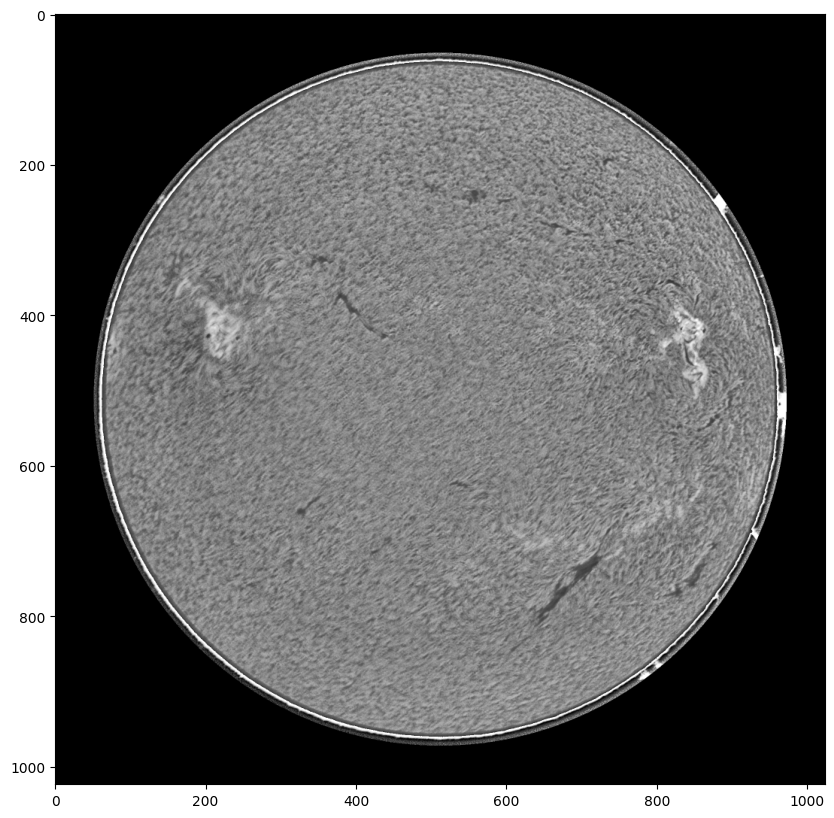

In [13]:
image, mask = val_dataset[11]

image = image.squeeze().numpy()
mask = mask.squeeze().numpy()

plt.figure(figsize=(10, 10), dpi=100)
plt.imshow(image, cmap="gray")
plt.show()

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Model</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> Everything in the model revolves around one signal, the local edge orientation. It is computed once from the input and reused at the bottleneck, in the decoder and at the full-resolution output, so the network always has the geometry at hand.</p></div></div>

In [14]:
# Helpers
def CNR_block(in_channels: int, out_channels: int, dilation: int = 1) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=dilation, dilation=dilation, bias=False),
        nn.GroupNorm(8, out_channels),
        nn.ReLU(inplace=True),
    )

class DecoderBlock(nn.Module):
    def __init__(self, in_channels: int, skip_channels: int, out_channels: int):
        super().__init__()
        self.conv = nn.Sequential(
            CNR_block(in_channels + skip_channels, out_channels),
            CNR_block(out_channels, out_channels),
        )

    def forward(self,
                features: torch.Tensor,
                skip: torch.Tensor) -> torch.Tensor:
        upsampled = F.interpolate(
            features, size=skip.shape[-2:], mode="bilinear", align_corners=False
        )

        return self.conv(torch.cat([upsampled, skip], dim=1))

def ADPM(moments, size, num_scales):
    B, C, H, W = moments.shape
    moments = moments.reshape(B, num_scales * 3, H, W)
    return F.adaptive_avg_pool2d(moments, size)


def partition_windows(x, window_size):
    B, C, H, W = x.shape

    return (
        x.reshape(B, C, H // window_size, window_size, W // window_size, window_size)
        .permute(0, 2, 4, 3, 5, 1)
        .reshape(-1, window_size * window_size, C)
    )


def reverse_windows(windows, batch_size, height, width, window_size):
    C = windows.shape[-1]

    return (
        windows.reshape(
            batch_size, height // window_size, width // window_size, window_size, window_size, C
        )
        .permute(0, 5, 1, 3, 2, 4)
        .reshape(batch_size, C, height, width)
    )

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> This is the core of my solution. I believe the shape of a filament is what separates it from sunspots and other structures, so the model gets the orientation explicitly: fixed Kirsch edge filters give the direction and strength of the edges at 3 scales. This orientation field guides an attention block on the encoder features (ResNet-34), conditions every decoder stage and goes into the last decoder block.</p></div></div>

In [15]:
class KirschFilters(nn.Module):
    """Compute positive and negative Kirsch responses at each configured scale.

    The fixed eight-direction filter bank provides the directional responses
    later aggregated into the multi-scale orientation field.

    Args:
        dilations: Spatial dilation rates applied to the filter bank.
    """
    def __init__(self, dilations=(1, 2, 4)):
        super().__init__()

        kernels = torch.tensor(
            [
                [
                    [5, 5, 5],
                    [-3, 0, -3],
                    [-3, -3, -3],
                ],
                [
                    [-3, 5, 5],
                    [-3, 0, 5],
                    [-3, -3, -3],
                ],
                [
                    [-3, -3, 5],
                    [-3, 0, 5],
                    [-3, -3, 5],
                ],
                [
                    [-3, -3, -3],
                    [-3, 0, 5],
                    [-3, 5, 5],
                ],
                [
                    [-3, -3, -3],
                    [-3, 0, -3],
                    [5, 5, 5],
                ],
                [
                    [-3, -3, -3],
                    [5, 0, -3],
                    [5, 5, -3],
                ],
                [
                    [5, -3, -3],
                    [5, 0, -3],
                    [5, -3, -3],
                ],
                [
                    [5, 5, -3],
                    [5, 0, -3],
                    [-3, -3, -3],
                ],
            ],
            dtype=torch.float32,
        ).unsqueeze(1) / 15

        self.register_buffer("kernels", kernels)
        self.dilations = dilations

    def forward(self, image):
        responses = []

        for dilation in self.dilations:
            padded = F.pad(
                image,
                (dilation,) * 4,
                mode="replicate"
            )

            response = F.conv2d(
                padded,
                self.kernels,
                dilation=dilation
            )

            positive = F.relu(response)
            negative = F.relu(-response)

            responses.append(
                torch.cat([positive, negative], dim=1)
            )

        return torch.cat(responses, dim=1)


class OrientationFieldExtractor(nn.Module):
    """Aggregate Kirsch responses into per-scale orientation moments.

    For each scale, combines the eight directions into two doubled-angle
    components and a response-energy map. ``normalize`` converts these
    moments into direction components and log-magnitude.

    Args:
        num_scales: Number of scales represented in the response tensor.
        tau: Stabilizer used when normalizing the direction components.
    """
    def __init__(self,
                 num_scales=3,
                 tau=0.1):
        super().__init__()

        k = torch.arange(8, dtype=torch.float32) * (torch.pi / 4)

        self.register_buffer(
            "cosines",
            torch.cos(2 * k).view(1, 8, 1, 1)
        )

        self.register_buffer(
            "sines",
            torch.sin(2 * k).view(1, 8, 1, 1)
        )

        self.num_scales = num_scales
        self.tau = tau

    def forward(self, responses):
        B, C, H, W = responses.shape

        responses = responses.reshape(B, self.num_scales, 16, H, W)

        positive, negative = responses.split(8, dim=2)
        weights = positive + negative

        vx = (weights * self.cosines.unsqueeze(1)).sum(dim=2)
        vy = (weights * self.sines.unsqueeze(1)).sum(dim=2)
        energy = weights.sum(dim=2)

        out = (
            torch.stack(
                [vx, vy, energy],
                dim=2
            ).reshape(B, self.num_scales * 3, H, W)
        )

        return out

    def normalize(self, moments):
        B, C, H, W = moments.shape

        moments = moments.reshape(
            B, self.num_scales, 3, H, W
        )

        vx, vy, energy = moments.unbind(dim=2)

        direction_x = vx / (energy + self.tau)
        direction_y = vy / (energy + self.tau)
        magnitude = torch.log1p(energy)

        orientation = torch.stack(
            [direction_x,
             direction_y,
             magnitude],
            dim=2
        )

        return orientation.reshape(B, self.num_scales * 3, H, W)


class CompassAttention(nn.Module):
    """Apply windowed self-attention with an orientation-dependent bias.

    Args:
        dim: Number of input and output feature channels.
        num_heads: Number of attention heads.
        window_size: Side length of each non-overlapping attention window.
        orientation_dim: Number of orientation input channels.
        num_scales: Number of orientation scales.
    """

    def __init__(self,
                 dim,
                 num_heads=8,
                 window_size=8,
                 orientation_dim=9,
                 num_scales=3):
        super().__init__()

        self.window_size = window_size
        self.num_heads = num_heads
        self.num_scales = num_scales
        self.head_dim = dim // num_heads
        self.scale = self.head_dim**(-0.5)

        self.extractor = OrientationFieldExtractor(num_scales=num_scales)

        self.pos = nn.Conv2d(dim, dim, 3, padding=1, groups=dim)
        self.orientation_proj = nn.Conv2d(orientation_dim, dim, 1)

        self.norm1 = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, dim * 3)
        self.attention_proj = nn.Linear(dim, dim)

        self.norm2 = nn.LayerNorm(dim)

        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 2),
            nn.GELU(),
            nn.Linear(dim * 2, dim),
        )

        self.proj = nn.Conv2d(dim, dim, 1)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

        self.bias_scale = nn.Parameter(torch.ones(num_heads))

        coords = torch.stack(
            torch.meshgrid(
                torch.arange(window_size),
                torch.arange(window_size),
                indexing="ij",
            ),
            dim=-1,
        ).float().reshape(-1, 2).flip(-1)

        delta = coords.unsqueeze(0) - coords.unsqueeze(1)
        delta = delta / torch.linalg.vector_norm(
            delta, dim=-1, keepdim=True
        ).clamp_min(1e-6)

        self.register_buffer("relative_direction", delta)

    def directional_bias(self, orientation_moments):
        B, C, H, W = orientation_moments.shape

        moments = orientation_moments.reshape(
            B, self.num_scales, 3, H, W
        )

        vx, vy, energy = moments.unbind(dim=2)

        vx = vx.sum(dim=1)
        vy = vy.sum(dim=1)
        energy = energy.sum(dim=1)

        double = F.normalize(
            torch.stack([vx, vy], dim=1), dim=1, eps=1e-6
        )

        confidence = (
            torch.sqrt(vx.square() + vy.square()) / (energy + 1e-6)
        ).clamp(0, 1).unsqueeze(1)

        double_windows = partition_windows(double, self.window_size)
        confidence_windows = partition_windows(
            confidence, self.window_size
        ).squeeze(-1)

        pair_double = F.normalize(
            double_windows.unsqueeze(2) + double_windows.unsqueeze(1),
            dim=-1, eps=1e-6,
        )

        rel = self.relative_direction.to(
            device=double.device, dtype=double.dtype
        )
        dx, dy = rel[..., 0], rel[..., 1]
        rel_double = torch.stack([dx * dx - dy * dy, 2 * dx * dy], dim=-1)

        alignment_sq = 0.5 * (
            1 + (pair_double * rel_double.unsqueeze(0)).sum(dim=-1)
        )

        pair_confidence = (
            confidence_windows.unsqueeze(2)
            + confidence_windows.unsqueeze(1)
        ) * 0.5

        bias = alignment_sq * pair_confidence

        return (
            bias.unsqueeze(1)
            * self.bias_scale.view(1, self.num_heads, 1, 1)
        )

    def forward(self, features, orientation_moments):
        identity = features
        B, C, H, W = features.shape
        window_size = self.window_size

        pad_h = (window_size - H % window_size) % window_size
        pad_w = (window_size - W % window_size) % window_size

        features = F.pad(features, (0, pad_w, 0, pad_h))
        Hp, Wp = features.shape[-2:]

        orientation_moments = ADPM(
            orientation_moments, (H, W), self.num_scales
        )
        orientation_moments = F.pad(orientation_moments, (0, pad_w, 0, pad_h))

        orientation = self.extractor.normalize(orientation_moments)

        features = features + self.pos(features)
        Z = features + self.orientation_proj(orientation)

        tokens = partition_windows(Z, window_size)
        normalized = self.norm1(tokens)

        Bn, N, _ = normalized.shape

        qkv = self.qkv(normalized).reshape(
            Bn, N, 3,
            self.num_heads,
            self.head_dim
        ).permute(2, 0, 3, 1, 4)

        q, k, v = qkv.unbind(dim=0)

        logits = (q @ k.transpose(-2, -1)) * self.scale
        logits = logits + self.directional_bias(orientation_moments)

        attention = logits.softmax(dim=-1)
        attended = attention @ v

        attended = attended.transpose(1, 2).reshape(Bn, N, C)

        tokens = tokens + self.attention_proj(attended)
        tokens = tokens + self.mlp(self.norm2(tokens))

        output = reverse_windows(tokens, B, Hp, Wp, window_size)
        output = self.proj(output)
        output = output[:, :, :H, :W]

        return identity + output


class OrientationConditioning(nn.Module):
    """Condition decoder features on the multi-scale orientation field.

    Args:
        orientation_dim: Number of input orientation channels.
        channels: Number of feature channels to produce.
        num_scales: Number of orientation scales.
    """
    def __init__(self, orientation_dim, channels, num_scales=3):
        super().__init__()

        self.num_scales = num_scales
        self.proj = nn.Sequential(
            nn.Conv2d(orientation_dim, channels, 1, bias=False),
            nn.GroupNorm(8, channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.GroupNorm(8, channels),
        )

        self.alpha = nn.Parameter(torch.zeros(1))

    def forward(self, features, orientation_moments):
        moments = ADPM(
            orientation_moments,
            features.shape[-2:],
            self.num_scales,
        )

        B, C, H, W = moments.shape
        moments = moments.reshape(B, self.num_scales, 3, H, W)

        vx, vy, energy = moments.unbind(dim=2)

        orientation = torch.stack(
            [
                vx / (energy + 0.1),
                vy / (energy + 0.1),
                torch.log1p(energy),
            ],
            dim=2,
        ).reshape(B, self.num_scales * 3, H, W)

        out = features + self.alpha * self.proj(orientation)

        return out


class KirschCompass(nn.Module):
    """Convert an input image into raw and normalized orientation fields.

    Args:
        dilations: Spatial dilation rates used by the Kirsch filters.
    """
    def __init__(self, dilations=(1, 2, 4)):
        super().__init__()
        D = len(dilations)
        self.filters = KirschFilters(dilations)
        self.extractor = OrientationFieldExtractor(num_scales=D)
        self.out_channels = 3 * len(dilations)

    def moments(self, image):
        with torch.autocast(device_type=image.device.type, enabled=False):
            image = image.float()

            mean = image.mean(dim=(-2, -1), keepdim=True)
            std = image.std(
                dim=(-2, -1), keepdim=True, unbiased=False
            ).clamp_min(1e-6)

            image = (image - mean) / std
            responses = self.filters(image)

            return self.extractor(responses)

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        moments = self.moments(image)
        return self.extractor.normalize(moments)


class CompassNet(nn.Module):
    """Orientation-Aware U-Net with ResNet34 backbone.

    Args:
        dropout: Dropout probability applied to the deepest encoder features.
        weights_path: ``"native"`` for ImageNet weights, a checkpoint path,
            or ``None`` for randomly initialized backbone weights.
        num_heads: Number of heads in the orientation-guided attention.
        dilations: Spatial scales used by the Kirsch filter bank.
        spine: Whether to return an auxiliary spine prediction.
        freeze_bn: Whether to freeze the encoder's BatchNorm layers (for small batch sizes)

    Returns:
        Segmentation logits with one channel, or two when ``spine=True``.
    """
    def __init__(
        self,
        dropout: float = 0.05,
        weights_path: str | None = None,
        num_heads: int = 8,
        dilations=(1, 2, 4),
        spine: bool = False,
        freeze_bn: bool = True
    ):
        super().__init__()

        self.spine = spine
        self.freeze_bn = freeze_bn

        if weights_path == "native":
            weights = ResNet34_Weights.IMAGENET1K_V1
        else:
            weights = None

        backbone = torchvision.models.resnet34(weights=weights)

        self.kirsch = KirschCompass(dilations)
        D = self.kirsch.out_channels
        num_scales = len(dilations)

        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)
        self.pool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.compass_attention = CompassAttention(
            256,
            num_heads=num_heads,
            window_size=8,
            orientation_dim=D,
            num_scales=num_scales,
        )

        self.dropout = nn.Dropout2d(dropout)

        self.dec4 = DecoderBlock(512, 256, 256)
        self.dec3 = DecoderBlock(256, 128, 128)
        self.dec2 = DecoderBlock(128, 64, 64)
        self.dec1 = DecoderBlock(64, 64, 64)
        self.dec0 = DecoderBlock(64, 1 + D, 64)

        self.orient4 = OrientationConditioning(D, 256, num_scales)
        self.orient3 = OrientationConditioning(D, 128, num_scales)
        self.orient2 = OrientationConditioning(D, 64, num_scales)
        self.orient1 = OrientationConditioning(D, 64, num_scales)

        self.head = nn.Conv2d(64, 1, 1)

        if self.spine:
            self.spine_head = (
                nn.Sequential(CNR_block(64, 64), nn.Conv2d(64, 1, 1))
            )

        if weights_path is not None and weights_path != "native":
            self.load(weights_path)

        if self.freeze_bn:
            self.freeze_backbone_bn()

    def freeze_backbone_bn(self):
        for m in [self.stem,
                  self.layer1,
                  self.layer2,
                  self.layer3,
                  self.layer4]:
            for child in m.modules():
                if isinstance(child, (nn.BatchNorm2d, nn.SyncBatchNorm)):
                    child.eval()
                    for p in child.parameters():
                        p.requires_grad = False

    def train(self, mode: bool = True):
        super().train(mode)
        if self.freeze_bn:
            self.freeze_backbone_bn()
        return self

    def load(self, weights_path: str):
        state_dict = torch.load(weights_path, map_location="cpu")
        model_state = self.state_dict()
    
        state_dict = {
            k: v for k, v in state_dict.items()
            if k in model_state and v.shape == model_state[k].shape
        }
    
        self.load_state_dict(state_dict, strict=False)

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        orientation_moments = self.kirsch.moments(image)
        orientation = self.kirsch.extractor.normalize(orientation_moments)

        backbone_input = (image - 0.449) / 0.226
        backbone_input = backbone_input.repeat(1, 3, 1, 1)

        stem_features = self.stem(backbone_input)
        layer1_features = self.layer1(self.pool(stem_features))
        layer2_features = self.layer2(layer1_features)
        layer3_features = self.layer3(layer2_features)

        layer3_features = self.compass_attention(
            layer3_features, orientation_moments
        )

        deep_features = self.layer4(layer3_features)
        features = self.dropout(deep_features)

        features = self.dec4(features, layer3_features)
        features = self.orient4(features, orientation_moments)

        features = self.dec3(features, layer2_features)
        features = self.orient3(features, orientation_moments)

        features = self.dec2(features, layer1_features)
        features = self.orient2(features, orientation_moments)

        features = self.dec1(features, stem_features)
        features = self.orient1(features, orientation_moments)

        full_resolution_input = torch.cat([image, orientation], dim=1)
        features = self.dec0(features, full_resolution_input)

        mask = self.head(features)

        if self.spine:
            spine = self.spine_head(features)
            return torch.cat([mask, spine], dim=1)

        return mask

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Training</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

In [16]:
def set_optimizer(model, optimizer_fn, lr, weight_decay):
    decay_params = []
    no_decay_params = []
    bias_scale_params = []

    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if name.endswith("bias_scale"):
            bias_scale_params.append(param)
        elif "bias" in name or param.ndim == 1:
            no_decay_params.append(param)
        else:
            decay_params.append(param)

    return optimizer_fn(
        [
            {"params": decay_params, "weight_decay": weight_decay},
            {"params": no_decay_params, "weight_decay": 0.0},
            {"params": bias_scale_params, "weight_decay": 0.0, "eps": 1e-16},
        ],
        lr=lr,
    )

@torch.no_grad()
def validate(model, val_dataset, loss_fn=None, device=CFG.device):
    if loss_fn is None:
        loss_fn = BCEDiceLoss()
    model.eval()
    total_loss, n = 0.0, 0

    for img, mask in tqdm(val_dataset, desc="Validate"):
        img = img.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        with torch.amp.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")):
            output = model(img)

        loss = loss_fn(output.float(), mask.float())
        total_loss += loss.item()
        n += 1

    return total_loss / max(n, 1)

def train_loop(
    model: nn.Module,
    train_dataset: torch.utils.data.DataLoader,
    val_dataset: torch.utils.data.DataLoader,
    epochs: int = 5,
    lr: float = CFG.lr,
    weight_decay: float = 1e-4,
    device: torch.device = CFG.device,
    optimizer_fn: Callable = torch.optim.AdamW,
    loss_fn=None,
    val_loss_fn=None,
    patience: int = 5,
    path: str = "best.pt",
):
    if loss_fn is None:
        loss_fn = SegSpineLoss(spine_weight=0.1)
    if val_loss_fn is None:
        val_loss_fn = loss_fn

    optimizer = set_optimizer(
        model=model,
        lr=lr,
        optimizer_fn=optimizer_fn,
        weight_decay=weight_decay,
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    model.to(device)

    history = defaultdict(list)
    best_val = float("inf")
    val_loss = 0.0
    count = 0

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        batches = 0
        pbar = tqdm(train_dataset, desc=f"Epoch {epoch + 1}/{epochs}")

        for batch, (img, mask) in enumerate(pbar):
            img = img.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)

            optimizer.zero_grad()
            with torch.amp.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")):
                output = model(img)
                loss = loss_fn(output.float(), mask.float())

            loss_sum += loss.item()
            batches += 1
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            pbar.set_postfix(
                val=f"{val_loss:.4f}",
                loss=f"{loss_sum / batches:.4f}",
                lr=f"{optimizer.param_groups[0]['lr']:.6f}",
            )

        scheduler.step()
        val_loss = validate(model, val_dataset, val_loss_fn, device)

        history["val_loss"].append(val_loss)
        history["epoch"].append(epoch)
        history["train_loss"].append(loss_sum / batches)

        if val_loss < best_val:
            count = 0
            best_val = val_loss
            torch.save(model.state_dict(), path)
        else:
            count += 1

        if count > patience:
            print(f"Stopped early on epoch {epoch}")
            return history

    return history

In [17]:
checkpoint = "models/cnet@1024x567.pt"

In [19]:
cnet = CompassNet(
    dropout=0.1, 
    weights_path=None,
    freeze_bn=True, 
    num_heads=4,
    dilations=(1, 2, 4),
    spine=True
)

history = train_loop(
    cnet, 
    val_loader, # !! Change to train_loader. This is here only because I don't want to run it fully.
    val_loader, 
    epochs=1,
    path=f"cnet@{CFG.resolution}x{CFG.seed}.pt",
    loss_fn=SegSpineLoss(spine_weight=0.1),
    val_loss_fn=SegSpineLoss(seg_only=True),
    patience=100
)

Validate: 100%|██████████| 56/56 [00:54<00:00,  1.03it/s]


In [21]:
cnet.load_state_dict(
    torch.load(checkpoint, map_location=CFG.device)
)

<All keys matched successfully>

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Post Processing</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> At inference each image is predicted under the 8 flips and rotations, and the probabilities are averaged (TTA).</p></div></div>

In [22]:
# Post Processing and Evaluation
def evaluate_metrics(model, loader, device=CFG.device, threshold=0.5):
    model.eval()
    iou = BinaryJaccardIndex().to(device)
    precision = BinaryPrecision().to(device)
    recall = BinaryRecall().to(device)
    f1 = BinaryF1Score().to(device)

    for img, mask in tqdm(loader, desc="Metrics"):
        img = img.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        with torch.amp.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")):
            logits = model(img)

        if logits.shape[1] > 1:
            logits = logits[:, :1]
        if mask.shape[1] > 1:
            mask = mask[:, :1]

        pred = (torch.sigmoid(logits.float()) > threshold).long()
        target = (mask > 0.5).long()

        iou.update(pred, target)
        precision.update(pred, target)
        recall.update(pred, target)
        f1.update(pred, target)

    return {
        "iou": iou.compute().item(),
        "precision": precision.compute().item(),
        "recall": recall.compute().item(),
        "f1": f1.compute().item(),
    }

In [23]:
def apply(x, k, flip):
    if flip:
        x = torch.flip(x, dims=(-1,))
    x = torch.rot90(x, k, dims=(-2, -1))
    return x


def invert(y, k, flip):
    y = torch.rot90(y, -k, dims=(-2, -1))
    if flip:
        y = torch.flip(y, dims=(-1,))
    return y


@torch.no_grad()
def TTA_predict(model, x):
    total = 0
    for flip in (False, True):
        for k in range(4):
            augmented = apply(x, k, flip)
            logits = model(augmented)
            prob = torch.sigmoid(logits)
            prob = invert(prob, k, flip)
            total = total + prob
    return total / 8

In [24]:
@torch.no_grad()
def predict(model, x):
    logits = model(x)
    return torch.sigmoid(logits)


@torch.no_grad()
def probabilities(model, loader, predict_fn=TTA_predict, device=CFG.device):
    model.to(device)
    model.eval()
    probs = []
    targets = []
    for img, mask in tqdm(loader, desc=getattr(predict_fn, "__name__", "predict")):
        img = img.to(device)
        prob = predict_fn(model, img)
        prob = prob[:, :1].cpu() if prob.shape[1] > 1 else prob.cpu()
        probs.append(prob)

        target = mask[:, :1] if mask.shape[1] > 1 else mask
        target = (target > 0.5).long()
        targets.append(target)

    probs = torch.cat(probs)
    targets = torch.cat(targets)
    return probs, targets

# From https://github.com/irisaltHu/MORDEN/blob/main/segmentation/utils/post_processing/tools/hole_filling.py
def fill_hole_and_denoise(mask, threshold=5):
    contours, hierarchy = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    canvas = np.zeros_like(mask, np.uint8)
    for i in range(len(contours)):
        tmp_canvas = np.zeros_like(mask, np.uint8)
        tmp_canvas = cv2.drawContours(tmp_canvas, contours, i, 255, -1)
        if np.count_nonzero(tmp_canvas) >= threshold:
            canvas = np.logical_or(canvas, tmp_canvas)
    return canvas.astype(np.uint8)


def clean_mask(prob, threshold=0.5, min_area=5):
    mask = (prob > threshold).astype(np.uint8)
    mask = fill_hole_and_denoise(mask, min_area)
    return mask

In [25]:
def score(probs, targets, threshold=0.5, **params):
    iou = BinaryJaccardIndex()
    precision = BinaryPrecision()
    recall = BinaryRecall()
    f1 = BinaryF1Score()

    for prob, target in zip(probs, targets):
        prob_np = prob[0].numpy()
        mask = clean_mask(prob_np, threshold, **params)
        mask = torch.from_numpy(mask).long()
        target_t = target[0].long()

        iou.update(mask, target_t)
        precision.update(mask, target_t)
        recall.update(mask, target_t)
        f1.update(mask, target_t)

    return {
        "iou": iou.compute().item(),
        "precision": precision.compute().item(),
        "recall": recall.compute().item(),
        "f1": f1.compute().item(),
    }

In [31]:
# probs_tta, targets = probabilities(cnet, val_loader, TTA_predict)

def objective(trial):
    threshold = trial.suggest_float("threshold", 0.1, 0.9)
    min_area = trial.suggest_int("min_area", 10, 400, log=True)

    return score(
        probs_tta,
        targets,
        threshold=threshold,
        min_area=min_area,
    )["iou"]

# study = optuna.create_study(
#    direction="maximize",
#    sampler=optuna.samplers.TPESampler(seed=CFG.seed),
#)

# study.optimize(objective, n_trials=1, show_progress_bar=True) # 
# Must run with probabilities outputs

In [72]:
def plot_grid(
    model,
    dataset,
    indices,
    threshold=0.5,
    min_area=5,
    cell_size=6,
    dpi=300,
    save_path=None,
):
    device = next(model.parameters()).device
    model.eval()

    fig_h = len(indices) * cell_size
    fig, axes = plt.subplots(
        len(indices), 4, figsize=(4 * cell_size, fig_h), dpi=dpi, squeeze=False
    )

    for row, idx in zip(axes, indices):
        image, mask = dataset[idx]
        x = image.reshape(1, 1, *image.shape[-2:]).to(device)
        prob = predict(model, x)[0, 0].cpu().numpy()
        pred = clean_mask(prob, threshold, min_area)
        agreement = mask[0].numpy()

        kw = {"cmap": "gray", "interpolation": "nearest"}
        row[0].imshow(image.squeeze().numpy(), **kw)
        row[1].imshow(pred, vmin=0, vmax=1, **kw)
        row[2].imshow(agreement, vmin=0, vmax=1, **kw)
        row[3].imshow(agreement >= 1 - 1e-6, vmin=0, vmax=1, **kw)

        for ax in row:
            ax.axis("off")

    titles = ["Image", "Prediction", "All annotations", "All annotators agreed"]
    for ax, title in zip(axes[0], titles):
        ax.set_title(title, fontsize=16)

    fig.subplots_adjust(
        left=0, right=1, bottom=0, top=1 - 0.5 / fig_h, wspace=0.03, hspace=0.03
    )

    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=dpi)
    plt.show()

In [39]:
def visualize_prediction(model, image, mask, threshold=0.5, min_area=5, save_path=None):
    device = next(model.parameters()).device
    x = image.reshape(1, 1, *image.shape[-2:]).to(device)
    prob = predict(model.eval(), x)[0, 0].cpu().numpy()

    panels = [
        (image.squeeze().numpy(), "gray", "Input", {}),
        (mask[0].numpy(), "gray", "Ground truth", {"vmin": 0, "vmax": 1}),
        (prob, "viridis", "Probability", {"vmin": 0, "vmax": 1}),
        (clean_mask(prob, threshold, min_area), "gray", "Segmentation", {"vmin": 0, "vmax": 1}),
    ]

    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    for ax, (img, cmap, title, kw) in zip(axes, panels):
        ax.imshow(img, cmap=cmap, **kw)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

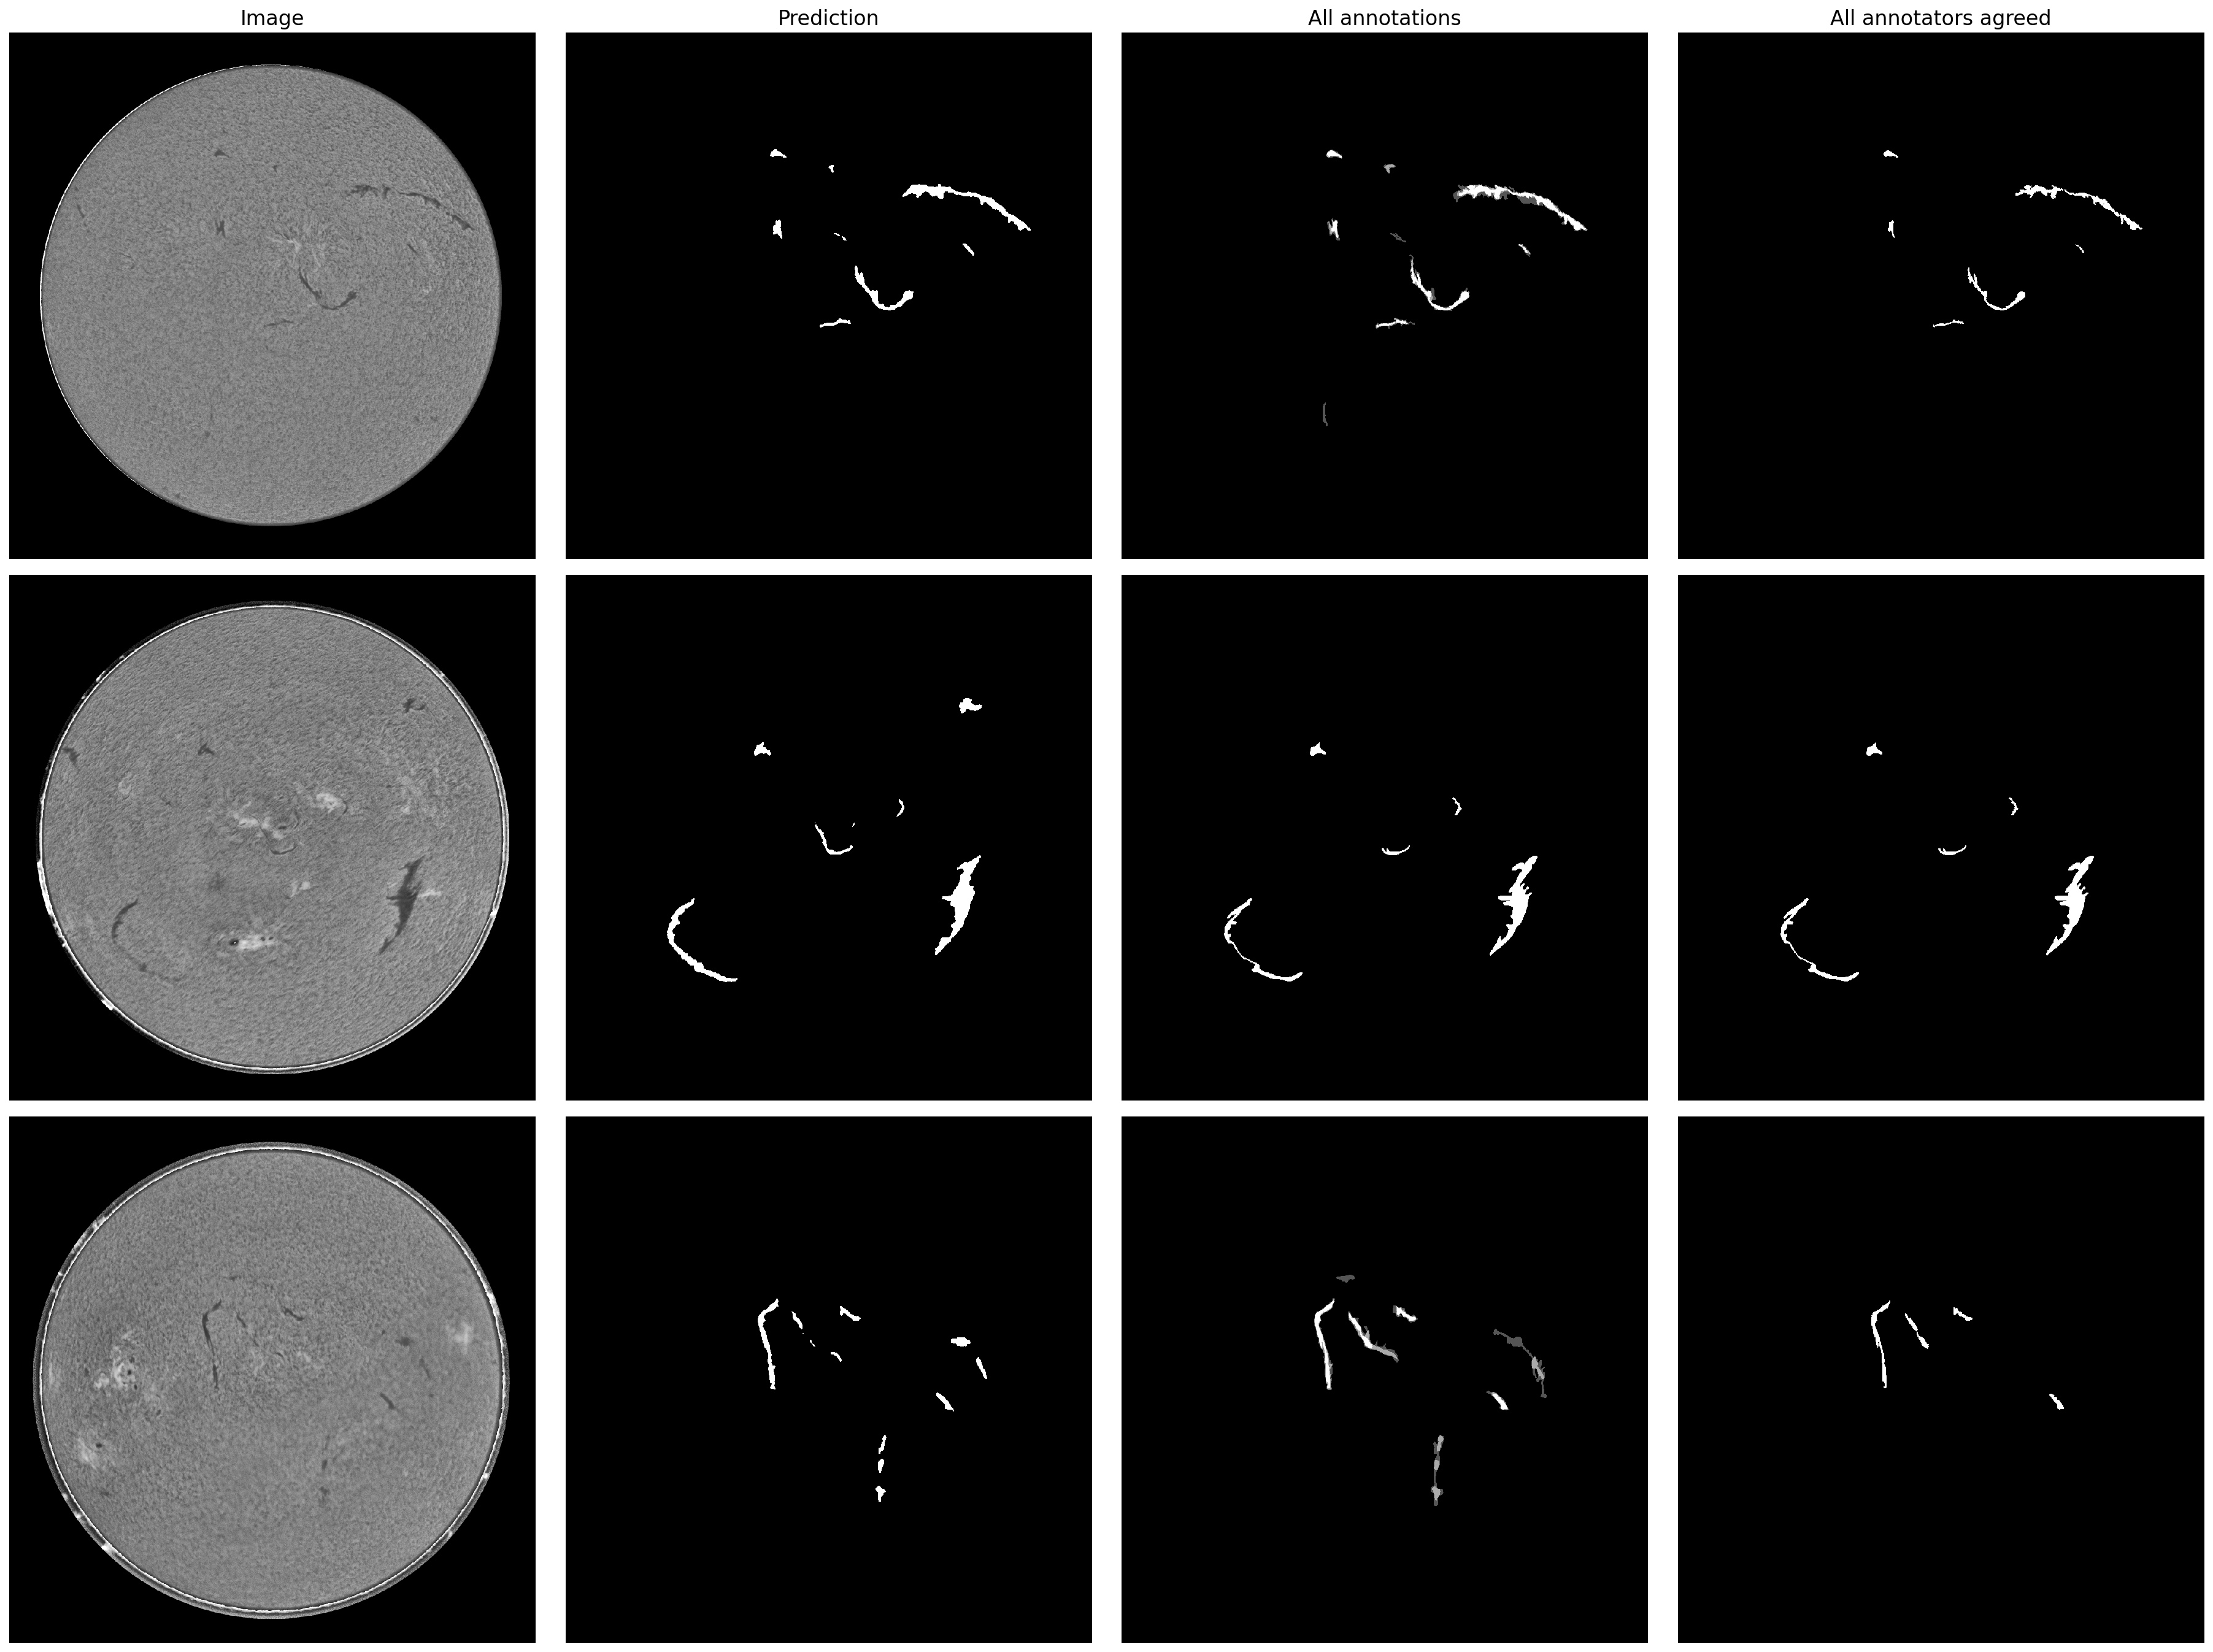

In [76]:
indices = [3, 25, 19]

plot_grid(cnet, val_dataset, indices, save_path="grid.png", dpi=150)

<div style="width:100%; box-sizing:border-box; border-radius:12px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.80), rgba(28, 34, 40, 0.80)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="padding:14px 24px;"><p style="margin:0; font-family:Georgia, 'Times New Roman', serif; font-size:15px; font-weight:normal; color:#FFFFFF; text-shadow:0 2px 10px rgba(0,0,0,0.95), 0 1px 3px rgba(0,0,0,1); line-height:1.6; text-align:left;"><span style="color:#EAD98B; font-weight:bold;">— </span> What the orientation field looks like on a predicted filament: the arrows show the edge direction, and their size and color show the strength.</p></div></div>

In [50]:
@torch.no_grad()
def plot_orientation_field(model, image, step=4, threshold=0.5, save_path=None):
    device = next(model.parameters()).device
    model.eval()

    captured = {}

    def hook(module, inputs, output):
        captured["orientation"] = (output[0] if isinstance(output, (tuple, list)) else output).cpu()

    handle = model.kirsch.extractor.register_forward_hook(hook)
    x = image.reshape(1, 1, *image.shape[-2:]).to(device)
    prob = predict(model, x)[0, 0].cpu().numpy()
    handle.remove()

    image = image.squeeze().numpy()
    vx, vy, energy = captured["orientation"][0].numpy()[:3]

    scale = np.log1p(energy) / (energy + 1e-3)
    mask = prob > threshold

    H_img, W_img = image.shape
    h, w = vx.shape

    win_h, win_w = int(H_img * 0.30), int(W_img * 0.30)
    density = uniform_filter(mask.astype(float), size=(win_h, win_w), mode="constant")
    cy, cx = np.unravel_index(density.argmax(), density.shape)

    y0 = int(np.clip(cy - win_h // 2, 0, H_img - win_h))
    x0 = int(np.clip(cx - win_w // 2, 0, W_img - win_w))
    y1, x1 = y0 + win_h, x0 + win_w

    crop = image[y0:y1, x0:x1].astype(float)
    p_lo, p_hi = np.percentile(crop, [1, 99])
    crop = np.clip((crop - p_lo) / (p_hi - p_lo + 1e-8), 0, 1)

    fy0, fy1 = int(y0 * h / H_img), int(y1 * h / H_img)
    fx0, fx1 = int(x0 * w / W_img), int(x1 * w / W_img)

    pooled = []
    for v in (vx * scale, vy * scale):
        v = v[fy0:fy1, fx0:fx1]
        hh, ww = v.shape[0] // step * step, v.shape[1] // step * step
        pooled.append(v[:hh, :ww].reshape(hh // step, step, ww // step, step).mean(axis=(1, 3)))
    Vx, Vy = pooled

    theta = 0.5 * np.arctan2(Vy, Vx) + np.pi / 2
    strength = np.hypot(Vx, Vy)

    lo, hi = np.percentile(strength, [5, 99.5])
    level = np.clip((strength - lo) / (hi - lo + 1e-8), 0, 1) ** 1.5

    sx, sy = W_img / w, H_img / h

    rows, cols = np.mgrid[0:theta.shape[0], 0:theta.shape[1]]
    A, L = theta.ravel(), level.ravel()
    X = ((cols + 0.5) * step * sx).ravel()
    Y = ((rows + 0.5) * step * sy).ravel()

    order = np.argsort(L)
    X, Y, A, L = X[order], Y[order], A[order], L[order]

    length = step * (sx + sy) / 2 * 1.5 * (0.45 + 0.55 * L)

    dx, dy = np.sin(A), -np.cos(A)
    nx, ny = -dy, dx

    half_shaft = length * (0.05 + 0.06 * L)
    half_head = np.maximum(half_shaft * 2.4, length * 0.2)
    head_len = length * 0.38

    tail_x, tail_y = X - dx * length / 2, Y - dy * length / 2
    tip_x, tip_y = X + dx * length / 2, Y + dy * length / 2
    base_x, base_y = tip_x - dx * head_len, tip_y - dy * head_len

    polys = np.stack(
        [
            np.stack([tail_x + nx * half_shaft, tail_y + ny * half_shaft], axis=-1),
            np.stack([base_x + nx * half_shaft, base_y + ny * half_shaft], axis=-1),
            np.stack([base_x + nx * half_head, base_y + ny * half_head], axis=-1),
            np.stack([tip_x, tip_y], axis=-1),
            np.stack([base_x - nx * half_head, base_y - ny * half_head], axis=-1),
            np.stack([base_x - nx * half_shaft, base_y - ny * half_shaft], axis=-1),
            np.stack([tail_x - nx * half_shaft, tail_y - ny * half_shaft], axis=-1),
        ],
        axis=1,
    )

    cmap = LinearSegmentedColormap.from_list(
        "indigo_to_yellow",
        ["#3b1c8c", "#8a1f8f", "#d6335a", "#ff7a1a", "#ffd43b", "#fff3a0"],
        N=256,
    )

    fig, ax = plt.subplots(figsize=(12, 9))
    ax.imshow(
        crop,
        cmap="gray",
        vmin=-0.5,
        vmax=1.5,
        extent=(0, crop.shape[1], crop.shape[0], 0),
    )

    arrows = PolyCollection(
        polys,
        array=L,
        cmap=cmap,
        norm=mpl.colors.Normalize(vmin=0, vmax=1),
        edgecolors="none",
        linewidths=0,
        antialiased=True,
    )
    ax.add_collection(arrows)
    plt.colorbar(arrows, ax=ax, label="Magnitude", fraction=0.04, pad=0.02)

    ax.set_xlim(0, crop.shape[1])
    ax.set_ylim(crop.shape[0], 0)
    ax.axis("off")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

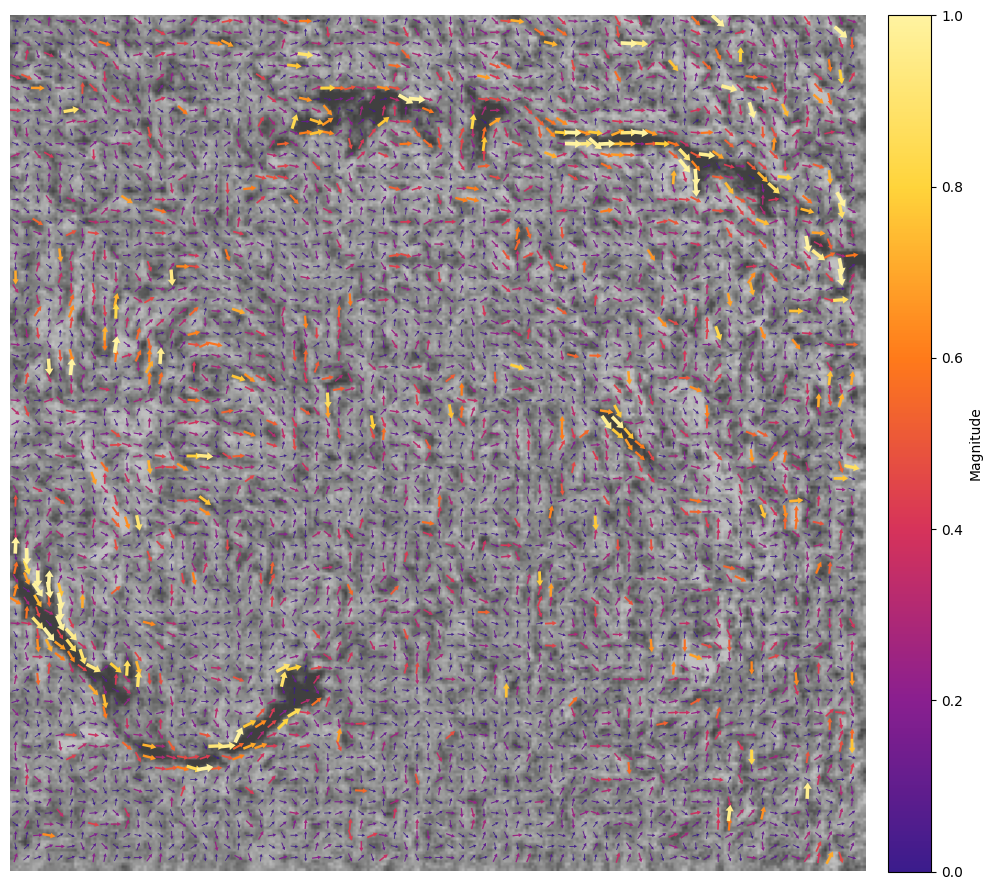

In [53]:
# Vectors are cool, we should use them more

image, mask = val_dataset[3]
plot_orientation_field(cnet, image, save_path="orientation_field.svg")

<div style="width:100%; box-sizing:border-box; border-radius:16px; overflow:hidden; background-color:#232A30; background-image:linear-gradient(rgba(28, 34, 40, 0.68), rgba(28, 34, 40, 0.68)), url('https://thumb.wikimedia.org/wikipedia/commons/thumb/c/c7/Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg/1920px-Pieter_Bruegel_the_Elder_-_Landscape_with_the_Fall_of_Icarus_-_Brussels%2C_Royal_Museums_of_Fine_Arts_of_Belgium_-_Google_Arts_%26_Culture.jpg?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail'); background-size:cover; background-position:center;"><div style="text-align:center; padding:28px 24px;"><p style="margin:0; font-family:'Courier New', Courier, monospace; font-size:12px; font-weight:bold; color:#FFF2A2; text-shadow:0 2px 10px rgba(0,0,0,0.95); letter-spacing:4px;">SECTION</p><p style="margin:8px 0 0 0; font-family:Arial, sans-serif; font-size:32px; font-weight:900; color:#FFFFFF; text-shadow:0 4px 20px rgba(0,0,0,0.95); line-height:1.1;">Submission</p><div style="width:48px; height:3px; background:#EAD98B; margin:14px auto 0 auto; border-radius:10px;"></div></div></div>

In [ ]:
def load_image(path, resolution, preprocess):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
    img = cv2.resize(preprocess(img), (resolution, resolution), interpolation=cv2.INTER_AREA)
    return torch.from_numpy(img)[None, None]


def predict_probability(model, x, predict_fn, out_size):
    with torch.inference_mode():
        prob = predict_fn(model, x)[0, 0].cpu().numpy()
    return cv2.resize(prob, (out_size, out_size), interpolation=cv2.INTER_LINEAR)


def encode_components(binary):
    n_labels, labels = cv2.connectedComponents(binary, connectivity=8)
    for k in range(1, n_labels):
        component = np.asfortranarray(labels == k, dtype=np.uint8)
        yield mask_util.encode(component)["counts"].decode("utf-8")


In [54]:
def make_submission(
    model,
    test_dir,
    resolution,
    device,
    predict_fn,
    preprocess,
    clean_mask,
    threshold=0.5,
    min_area=0,
    out_size=2048,
    output_path="submission.csv",
):
    model.eval().to(device)
    min_area = int(min_area * (out_size / resolution) ** 2)

    rows = []
    for path in tqdm(sorted(Path(test_dir).glob("*"))):
        x = load_image(path, resolution, preprocess).to(device)
        prob = predict_probability(model, x, predict_fn, out_size)
        binary = clean_mask(prob, threshold=threshold, min_area=min_area).astype(np.uint8)
        rows.extend(
            {"filament_id": f"{path.stem}_{k}", "segmentation_rle": counts}
            for k, counts in enumerate(encode_components(binary), start=1)
        )

    submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
    submission.to_csv(output_path, index=False)
    return submission

In [32]:
submission = make_submission(
    cnet,
    test_dir=CFG.test,
    resolution=CFG.resolution,
    device=CFG.device,
    predict_fn=TTA_predict,
    preprocess=preprocess,
    clean_mask=clean_mask,
    min_area=30, # or study best paramms
)

NameError: name 'make_submission' is not defined